# Inferensi segmentasi instance pada foto baru

**Evaluasi CPMK 3 · NRP 5054241018**

Notebook ini menggunakan checkpoint final skenario semua kelas dari Google Drive. YOLO11s-seg, Mask R-CNN, dan RF-DETR Seg Small memproses foto yang sama. Hasilnya berupa mask berwarna, label kelas, dan confidence tiap instance. Pada foto baru, hasil ini merupakan prediksi model.

1. Buka notebook di Google Colab dengan runtime **GPU** dan jalankan **Run all**.
2. Hubungkan Drive saat diminta. Pada bagian **3.1**, pilih satu foto JPG, PNG, atau WebP.
3. Untuk foto lain, jalankan bagian **3.1–5.3**. Untuk mengubah confidence pada foto yang sama, cukup jalankan ulang **5.1–5.3**.

Konfigurasi awal menjalankan ketiga model dan menyimpan satu gambar perbandingan ke Drive sebagai `perbandingan_model.png`. Untuk demo satu model, atur `MODELS = ["rfdetr"]` pada bagian **1.2** sebelum menjalankan inferensi.

### 1.1 Menghubungkan Google Drive

Mount Google Drive, periksa ketersediaan GPU, dan siapkan folder kerja lokal untuk inferensi.

In [43]:
import csv
import json
import re
import shutil
import site
import subprocess
import sys
import tempfile
import venv
from datetime import datetime, timezone
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from google.colab import drive, files
from IPython.display import display
from PIL import Image, ImageDraw, ImageFont, ImageOps, UnidentifiedImageError

gpu = subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True) if shutil.which("nvidia-smi") else None
if gpu is None or gpu.returncode or not gpu.stdout.strip():
    raise RuntimeError("Aktifkan runtime GPU di Colab, lalu jalankan ulang notebook.")
print(gpu.stdout.strip())

drive.mount("/content/drive")
RUNTIME_DIR = Path("/content/cpmk3_live_inference")
RUNTIME_DIR.mkdir(exist_ok=True)

GPU 0: Tesla T4 (UUID: GPU-7c9ee8c1-7b35-342e-a9d0-1faf16936c71)
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 1.2 Menentukan model dan direktori

Pengaturan ini memilih model dan menunjuk ke checkpoint terbaik dari run Colab yang digunakan dalam evaluasi akhir.

In [44]:
PROJECT = Path("/content/drive/MyDrive/Computer_Vision_Tugas_CPMK3")
OUTPUT_ROOT = PROJECT / "outputs"
TRAIN_COCO = PROJECT / "dataset/train/_annotations.coco.json"
MODELS = ["yolo11", "maskrcnn", "rfdetr"]
MAX_PHOTO_SIDE = 1600
SCORE_FLOOR = 0.05
MAX_DETECTIONS = 100

MODEL_SPECS = {
    "yolo11": ("YOLO11s-seg", "colab_quality01", "best.pt", "ultralytics==8.4.215"),
    "maskrcnn": ("Mask R-CNN", "colab_quality02", "best.pth", None),
    "rfdetr": ("RF-DETR Seg Small", "colab_quality01", "best.pth", "rfdetr[train]==1.12.1"),
}
if not MODELS or len(MODELS) != len(set(MODELS)) or set(MODELS) - MODEL_SPECS.keys():
    raise ValueError("Pilih model yang unik dari: yolo11, maskrcnn, rfdetr.")
if MAX_PHOTO_SIDE < 1:
    raise ValueError("MAX_PHOTO_SIDE harus berupa panjang sisi yang positif.")

### 1.3 Memeriksa checkpoint dan pemetaan kelas

Baca daftar kategori dari anotasi COCO training, lalu cocokkan urutan ID dengan konfigurasi checkpoint. Foto training tidak perlu disalin.

In [45]:
def read_json(path):
    if not path.is_file():
        raise FileNotFoundError(f"Berkas yang diperlukan tidak ditemukan: {path}")
    return json.loads(path.read_text(encoding="utf-8"))

train = read_json(TRAIN_COCO)
seen_ids = {ann["category_id"] for ann in train["annotations"]}
parents = {cat.get("supercategory") for cat in train["categories"]}
class_names = {
    cat["id"]: cat["name"]
    for cat in train["categories"]
    if not (cat["name"] in parents and cat["id"] not in seen_ids
            and cat.get("supercategory") != cat["name"])
}

model_configs = {}
for model in MODELS:
    title, run_label, filename, _ = MODEL_SPECS[model]
    folder = OUTPUT_ROOT / "artifacts" / model / "all_classes" / run_label
    checkpoint = folder / filename
    if not checkpoint.is_file():
        raise FileNotFoundError(f"Checkpoint {title} tidak ditemukan: {checkpoint}")
    config = read_json(folder / "run_config.json")
    expected = {"model": model, "run_label": run_label, "scenario": "all_classes",
                "category_ids": sorted(class_names), "smoke_test": False}
    for key, value in expected.items():
        if config.get(key) != value:
            raise ValueError(f"Nilai {key} pada konfigurasi {title} berbeda: {folder}")
    model_configs[model] = {
        "model": model, "checkpoint": str(checkpoint), "category_ids": config["category_ids"],
        "class_names": [class_names[cid] for cid in config["category_ids"]],
        "resolution": config["resolution"][model],
        "score_floor": SCORE_FLOOR, "max_detections": MAX_DETECTIONS,
    }
    print(f"{title}: {checkpoint}")
print(f"Jumlah kelas: {len(class_names)}")

YOLO11s-seg: /content/drive/MyDrive/Computer_Vision_Tugas_CPMK3/outputs/artifacts/yolo11/all_classes/colab_quality01/best.pt
Mask R-CNN: /content/drive/MyDrive/Computer_Vision_Tugas_CPMK3/outputs/artifacts/maskrcnn/all_classes/colab_quality02/best.pth
RF-DETR Seg Small: /content/drive/MyDrive/Computer_Vision_Tugas_CPMK3/outputs/artifacts/rfdetr/all_classes/colab_quality01/best.pth
Jumlah kelas: 74


### 2.1 Menyiapkan environment inferensi

Siapkan environment terpisah per model dengan versi paket dari evaluasi Colab. Environment dapat dipakai kembali selama runtime masih aktif.

In [46]:
def prepare_python(model):
    env = RUNTIME_DIR / "envs" / model
    python = env / "bin/python"
    if not python.is_file():
        venv.EnvBuilder(with_pip=False, system_site_packages=True).create(env)

    query = "import sysconfig; print(sysconfig.get_path('purelib'))"
    packages = Path(subprocess.check_output([str(python), "-c", query], text=True).strip())
    parent_paths = list(dict.fromkeys(site.getsitepackages() + [
        path for path in sys.path if path.endswith(("site-packages", "dist-packages"))
    ]))
    (packages / "runtime_parent.pth").write_text("\n".join(parent_paths), encoding="utf-8")

    requirement = MODEL_SPECS[model][3]
    stamp = env / "installed.txt"
    if requirement and (not stamp.exists() or stamp.read_text() != requirement):
        subprocess.run([str(python), "-m", "pip", "install", "-q", requirement], check=True)
        stamp.write_text(requirement, encoding="utf-8")
    return python

### 2.2 Memuat YOLO11s-seg

Adapter YOLO memakai ukuran inferensi dari konfigurasi training dan memetakan indeks model ke kelas COCO.

In [47]:
%%writefile /content/cpmk3_live_inference/predict_yolo11.py
import numpy as np
from PIL import Image
from ultralytics import YOLO


def predict(image, config):
    model = YOLO(config["checkpoint"])
    if [model.names[i] for i in range(len(model.names))] != config["class_names"]:
        raise ValueError("Urutan kelas checkpoint YOLO berbeda dari anotasi COCO.")

    result = model.predict(
        image, imgsz=config["resolution"], conf=config["score_floor"],
        max_det=config["max_detections"], retina_masks=True, device=0, verbose=False,
    )[0]
    if result.masks is None:
        return [], [], []
    masks = [
        np.asarray(Image.fromarray(mask > 0.5).resize(image.size, Image.Resampling.NEAREST))
        for mask in result.masks.data.cpu().numpy()
    ]
    return result.boxes.cls.cpu().numpy().astype(int), result.boxes.conf.cpu().numpy(), masks

Overwriting /content/cpmk3_live_inference/predict_yolo11.py


### 2.3 Memuat Mask R-CNN

Bangun kembali Mask R-CNN ResNet-50 FPN sesuai konfigurasi training dan muat bobot checkpoint. Ambang piksel mask adalah 0,50.

In [48]:
%%writefile /content/cpmk3_live_inference/predict_maskrcnn.py
import torch
from torchvision.models.detection import MaskRCNN
from torchvision.models.detection.backbone_utils import resnet_fpn_backbone
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from torchvision.ops import FrozenBatchNorm2d
from torchvision.transforms.functional import to_tensor


def predict(image, config):
    short, long = config["resolution"]
    backbone = resnet_fpn_backbone(
        backbone_name="resnet50", weights=None, norm_layer=FrozenBatchNorm2d, trainable_layers=3,
    )
    model = MaskRCNN(
        backbone, num_classes=91, min_size=short, max_size=long,
        box_score_thresh=config["score_floor"], box_detections_per_img=config["max_detections"],
    )
    for layer in model.modules():
        if isinstance(layer, FrozenBatchNorm2d):
            layer.eps = 0.0

    features = model.roi_heads.box_predictor.cls_score.in_features
    channels = model.roi_heads.mask_predictor.conv5_mask.in_channels
    classes = len(config["category_ids"]) + 1
    model.roi_heads.box_predictor = FastRCNNPredictor(features, classes)
    model.roi_heads.mask_predictor = MaskRCNNPredictor(channels, 256, classes)
    state = torch.load(config["checkpoint"], map_location="cpu", weights_only=False)
    model.load_state_dict(state["model"])
    del state
    model.to("cuda").eval()
    with torch.inference_mode():
        result = model([to_tensor(image).to("cuda")])[0]
        masks = result["masks"][:, 0].ge(0.5).cpu().numpy()
    return result["labels"].cpu().numpy() - 1, result["scores"].cpu().numpy(), masks

Overwriting /content/cpmk3_live_inference/predict_maskrcnn.py


### 2.4 Memuat RF-DETR Seg Small

Muat arsitektur dan bobot melalui API checkpoint RF-DETR. Keluarkan indeks background sebelum memetakan hasil ke kategori COCO.

In [49]:
%%writefile /content/cpmk3_live_inference/predict_rfdetr.py
import numpy as np
from rfdetr import RFDETR


def predict(image, config):
    model = RFDETR.from_checkpoint(config["checkpoint"], device="cuda")
    if list(model.class_names) != config["class_names"]:
        raise ValueError("Urutan kelas checkpoint RF-DETR berbeda dari anotasi COCO.")

    detections = model.predict(image, threshold=config["score_floor"])
    if detections.mask is None:
        return [], [], []
    labels = np.asarray(detections.class_id)
    scores = np.asarray(detections.confidence)
    if labels.ndim != 1 or scores.shape != labels.shape or len(detections.mask) != len(labels):
        raise ValueError("Dimensi output RF-DETR tidak konsisten.")
    if not np.isfinite(scores).all():
        raise ValueError("Confidence RF-DETR mengandung NaN atau Inf.")
    foreground = labels != len(config["category_ids"])
    return labels[foreground], scores[foreground], np.asarray(detections.mask)[foreground]

Overwriting /content/cpmk3_live_inference/predict_rfdetr.py


### 2.5 Menyeragamkan hasil inferensi

Worker menyimpan ID kategori, confidence, dan mask biner dalam format yang sama untuk ketiga model.

In [50]:
%%writefile /content/cpmk3_live_inference/worker.py
import importlib
import json
import sys
from pathlib import Path

import numpy as np
from PIL import Image


def normalize_predictions(image, config, labels, scores, masks):
    ids = np.asarray(config["category_ids"])
    labels, scores = np.asarray(labels, dtype=int), np.asarray(scores, dtype=np.float32)
    masks = np.asarray(masks, dtype=bool)
    if masks.shape == (0,):
        masks = masks.reshape(0, image.height, image.width)
    if labels.ndim != 1 or scores.shape != labels.shape or masks.shape != (len(labels), image.height, image.width):
        raise ValueError(f"Dimensi output {config['model']} tidak sesuai dengan foto.")
    if np.any((labels < 0) | (labels >= len(ids))) or not np.isfinite(scores).all():
        raise ValueError(f"Indeks kelas atau confidence {config['model']} tidak valid.")

    visible = masks.any(axis=(1, 2)) & (scores >= config["score_floor"])
    selected = np.flatnonzero(visible)
    order = selected[np.argsort(-scores[selected], kind="stable")][:config["max_detections"]]
    return ids[labels[order]], scores[order], masks[order]


if __name__ == "__main__":
    config_path, photo_path, output_path = sys.argv[1:]
    config = json.loads(Path(config_path).read_text(encoding="utf-8"))
    with Image.open(photo_path) as source:
        image = source.convert("RGB")
    adapter = importlib.import_module(f"predict_{config['model']}")
    ids, scores, masks = normalize_predictions(image, config, *adapter.predict(image, config))
    np.savez_compressed(output_path, category_ids=ids, scores=scores, masks=masks)

Overwriting /content/cpmk3_live_inference/worker.py


### 3.1 Mengunggah satu foto uji

Pilih satu foto dari perangkat. Notebook mengikuti orientasi EXIF dan membatasi sisi terpanjang ke 1.600 piksel secara default agar penggunaan memori GPU terkendali.

Saving gambar-random.jpg to gambar-random (1).jpg
gambar-random (1).jpg: 8160×6144 → 1600×1205 piksel


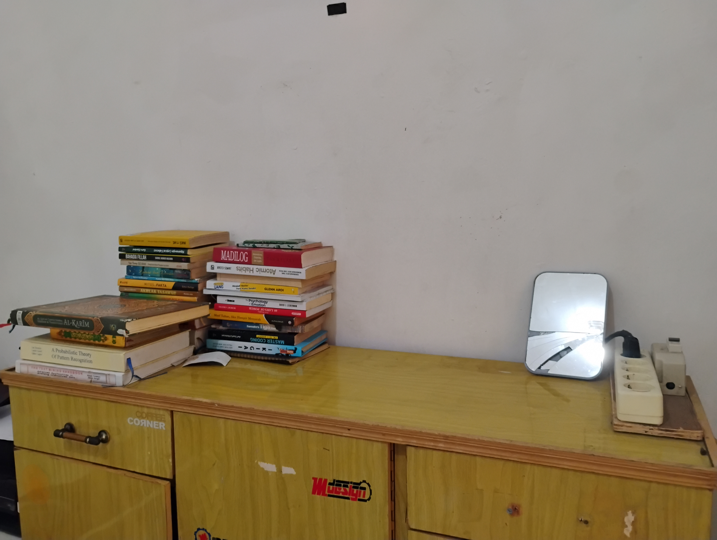

In [51]:
uploaded = files.upload()
if len(uploaded) != 1:
    raise ValueError("Pilih tepat satu foto, lalu jalankan ulang cell ini.")

photo_name, raw_photo = next(iter(uploaded.items()))
if Path(photo_name).suffix.lower() not in {".jpg", ".jpeg", ".png", ".webp"}:
    raise ValueError("Gunakan foto JPG, JPEG, PNG, atau WebP.")
try:
    with Image.open(BytesIO(raw_photo)) as source:
        photo = ImageOps.exif_transpose(source).convert("RGB")
except (UnidentifiedImageError, OSError) as exc:
    raise ValueError(f"Foto tidak bisa dibaca: {photo_name}") from exc

original_size = photo.size
photo.thumbnail((MAX_PHOTO_SIDE, MAX_PHOTO_SIDE), Image.Resampling.LANCZOS)
session_dir = Path(tempfile.mkdtemp(prefix="foto-", dir=RUNTIME_DIR))
photo_path = session_dir / "input.png"
photo.save(photo_path)
result_paths, model_errors = {}, {}
print(f"{photo_name}: {original_size[0]}×{original_size[1]} → {photo.width}×{photo.height} piksel")
display(ImageOps.contain(photo, (720, 540)))

### 4.1 Menjalankan inferensi

Jalankan model secara berurutan. Jika satu model gagal, hasil dari model yang selesai tetap dapat ditampilkan.

In [52]:
result_paths, model_errors = {}, {}
for model in MODELS:
    title = MODEL_SPECS[model][0]
    config_path = session_dir / f"{model}.json"
    config_path.write_text(json.dumps(model_configs[model]), encoding="utf-8")
    output_path = session_dir / f"{model}.npz"
    print(f"Menjalankan {title}...", flush=True)
    try:
        output_path.unlink(missing_ok=True)
        python = prepare_python(model)
        subprocess.run(
            [str(python), "-u", str(RUNTIME_DIR / "worker.py"), str(config_path),
             str(photo_path), str(output_path)],
            check=True,
        )
        if not output_path.is_file():
            raise FileNotFoundError(f"Arsip prediksi tidak ditemukan: {output_path}")
    except (subprocess.CalledProcessError, OSError) as exc:
        model_errors[model] = str(exc)
        print(f"{title} gagal. Periksa pesan worker di atas.")
        continue
    result_paths[model] = output_path

if not result_paths:
    raise RuntimeError("Inferensi seluruh model gagal. Periksa pesan worker di atas.")

Menjalankan YOLO11s-seg...
Menjalankan Mask R-CNN...
Menjalankan RF-DETR Seg Small...


### 5.1 Memilih confidence threshold

Gunakan nilai awal 0,25. Pengaturan ini memilih kandidat yang telah dihitung. Setelah mengubah nilai, jalankan ulang bagian 5.1–5.3.

In [53]:
CONFIDENCE = 0.25
SAVE_TO_DRIVE = True
if not SCORE_FLOOR <= CONFIDENCE <= 1:
    raise ValueError(f"CONFIDENCE harus berada pada rentang {SCORE_FLOOR} hingga 1,00.")

filtered = {}
prediction_rows = []
for model, path in result_paths.items():
    with np.load(path, allow_pickle=False) as output:
        keep = output["scores"] >= CONFIDENCE
        ids, scores, masks = (output[key][keep] for key in ("category_ids", "scores", "masks"))
    filtered[model] = (ids, scores, masks)
    for number, (cid, score) in enumerate(zip(ids, scores), start=1):
        prediction_rows.append({
            "model": MODEL_SPECS[model][0], "instance": number, "category_id": int(cid),
            "kelas": class_names[int(cid)], "confidence": round(float(score), 5),
        })

### 5.2 Menampilkan mask dan label

Panel membandingkan foto asli dengan hasil tiap model. Angka di depan label menunjukkan nomor instance pada tabel dan pada file hasil.

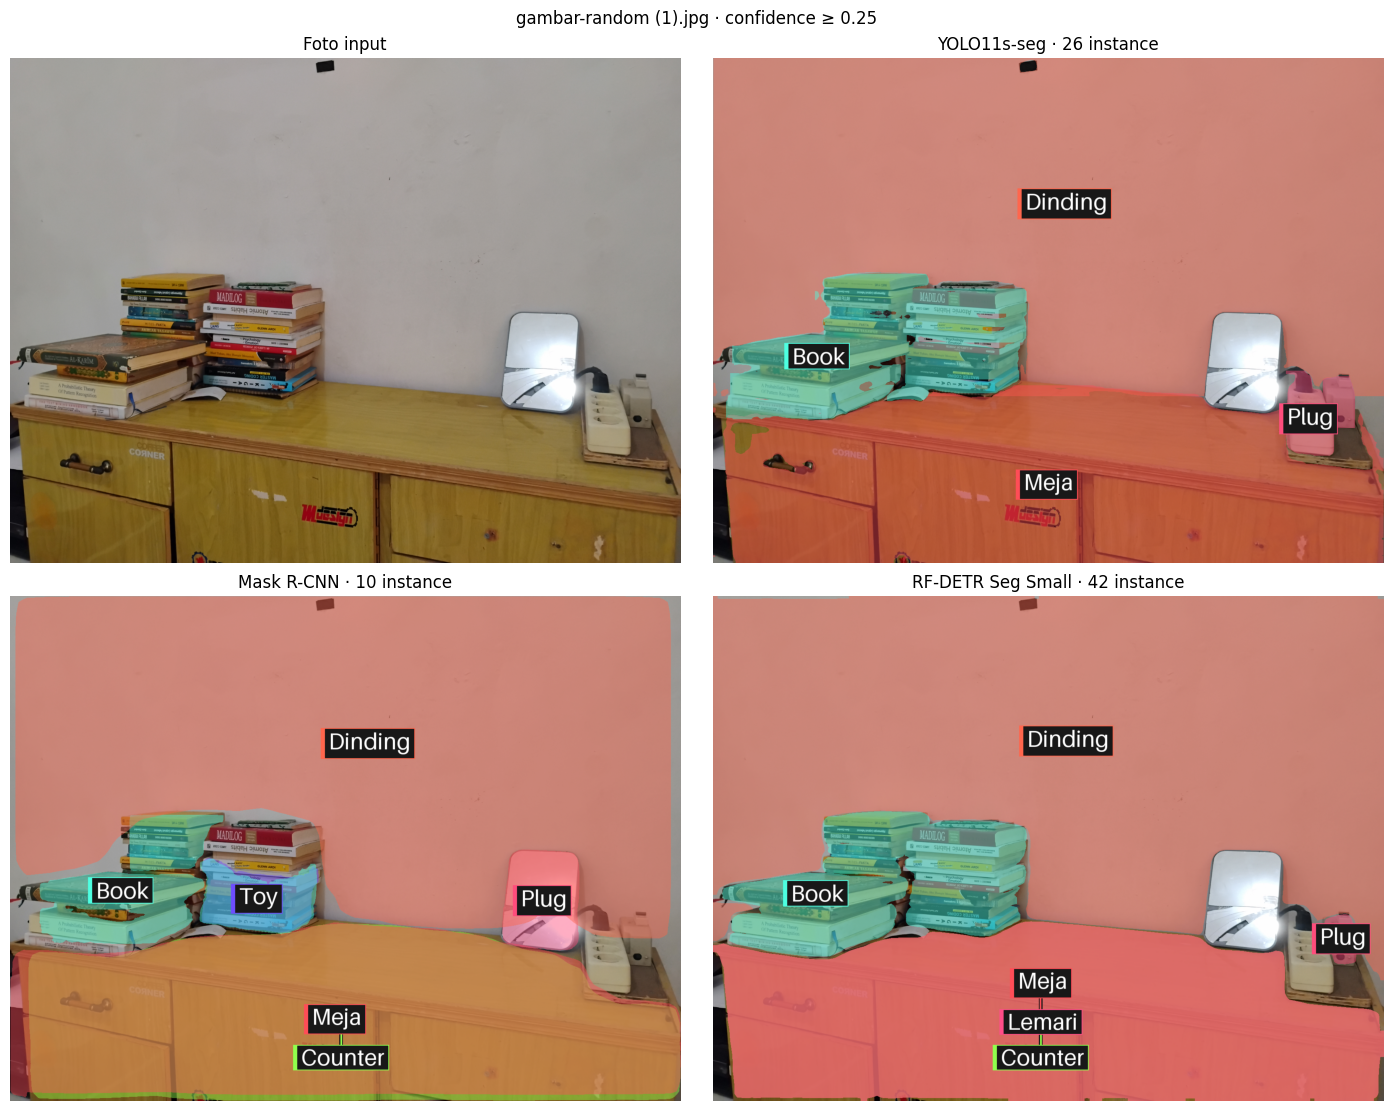

In [54]:
from colorsys import hsv_to_rgb

LABEL_SCALE = 0.034

DISPLAY_NAMES = {
    "backpack": "Tas",
    "handbag": "Tas",
    "chair": "Kursi",
    "floor-other-merged": "Lantai",
    "floor-wood": "Lantai",
    "table-merged": "Meja",
    "dining table": "Meja",
    "stairs": "Tangga",
    "ceiling-merged": "Plafon",
    "window-other": "Jendela",
    "door-stuff": "Pintu",
    "cabinet-merged": "Lemari",
}


def place_label(anchor, size, canvas, occupied):
    width, height = size
    max_x = max(0, canvas[0] - width - 1)
    max_y = max(0, canvas[1] - height - 1)
    left = max(0, min(anchor[0] - width // 2, max_x))
    top = max(0, min(anchor[1] - height // 2, max_y))

    xs = {left, max_x, *range(0, max_x + 1, max(1, width // 3))}
    ys = {top, max_y, *range(0, max_y + 1, height + 3)}
    positions = sorted(
        ((x, y) for x in xs for y in ys),
        key=lambda point: (abs(point[0] - left) + abs(point[1] - top), point),
    )

    for x, y in positions:
        if all(
            x + width + 2 < a or x > c + 2 or y + height + 2 < b or y > d + 2
            for a, b, c, d in occupied
        ):
            break
    else:
        x, y = left, top

    box = (x, y, x + width, y + height)
    occupied.append(box)
    return box


def draw_predictions(image, ids, scores, masks):
    groups = {}
    for index in np.argsort(-np.asarray(scores), kind="stable"):
        cid, mask = int(ids[index]), masks[index]
        name = class_names[cid]

        if name == "wall" or name.startswith("wall-"):
            label = "Dinding"
        else:
            label = DISPLAY_NAMES.get(name, name.removesuffix("-merged").capitalize())

        if label not in groups:
            groups[label] = (cid, mask.copy(), mask)
        else:
            merged_mask = groups[label][1]
            merged_mask |= mask

    pixels = np.array(image)
    tags = []
    for label, (cid, merged_mask, primary_mask) in reversed(groups.items()):
        color = tuple(
            round(255 * value) for value in hsv_to_rgb((cid * 0.618) % 1, 0.70, 1)
        )
        pixels[merged_mask] = 0.55 * pixels[merged_mask] + 0.45 * np.array(color)

        ys, xs = np.nonzero(primary_mask)
        nearest = np.argmin((xs - xs.mean()) ** 2 + (ys - ys.mean()) ** 2)
        anchor = (int(xs[nearest]), int(ys[nearest]))
        tags.append((anchor, label, color))

    overlay = Image.fromarray(pixels)
    draw = ImageDraw.Draw(overlay)
    font_size = max(12, round(image.width * LABEL_SCALE))

    try:
        font = ImageFont.truetype("DejaVuSans-Bold.ttf", font_size)
    except OSError:
        font = ImageFont.load_default(size=font_size)

    padding = max(3, font_size // 5)
    stripe = max(3, font_size // 6)
    occupied, placed = [], []

    for anchor, label, color in reversed(tags):
        a, b, c, d = draw.textbbox((0, 0), label, font=font)
        width = c - a + 2 * padding + stripe
        height = d - b + 2 * padding
        box = place_label(anchor, (width, height), image.size, occupied)
        placed.append((box, label, color, (a, b)))

        x1, y1, x2, y2 = box
        endpoint = (min(max(anchor[0], x1), x2), min(max(anchor[1], y1), y2))
        if endpoint != anchor:
            draw.line([anchor, endpoint], fill=(24, 24, 24), width=max(3, stripe))
            draw.line([anchor, endpoint], fill=color, width=max(1, stripe // 2))

    for (x1, y1, x2, y2), label, color, (a, b) in reversed(placed):
        draw.rectangle((x1, y1, x2, y2), fill=(24, 24, 24), outline=color, width=2)
        draw.rectangle((x1, y1, x1 + stripe, y2), fill=color)
        draw.text(
            (x1 + stripe + padding - a, y1 + padding - b),
            label,
            fill="white",
            font=font,
        )

    return overlay


overlays = {
    model: draw_predictions(photo, *predictions)
    for model, predictions in filtered.items()
}
panels = [("Foto input", photo)] + [
    (f"{MODEL_SPECS[model][0]} · {len(filtered[model][0])} instance", overlay)
    for model, overlay in overlays.items()
]

rows = (len(panels) + 1) // 2
figure_width = min(14, max(8, 10 * photo.width / photo.height + 2))
figure, axes = plt.subplots(
    rows, 2, figsize=(figure_width, 5.5 * rows),
    squeeze=False, layout="constrained",
)

for axis in axes.flat:
    axis.set_axis_off()
for axis, (title, image) in zip(axes.flat, panels):
    axis.imshow(image)
    axis.set_title(title)

figure.suptitle(f"{photo_name} · confidence ≥ {CONFIDENCE:.2f}")
plt.show()
plt.close(figure)

### 5.3 Merangkum dan menyimpan hasil

Tampilkan tabel prediksi. Jika penyimpanan diaktifkan, ekspor satu gambar perbandingan seluruh model ke Google Drive beserta foto input, overlay per model, tabel CSV, dan arsip mask biner. Baris mask pada arsip NPZ mengikuti urutan instance di tabel.

In [55]:
import pandas as pd

columns = ["model", "instance", "category_id", "kelas", "confidence"]
if prediction_rows:
    display(pd.DataFrame(prediction_rows, columns=columns))
else:
    print(f"Tidak ada instance dengan confidence ≥ {CONFIDENCE:.2f}.")
if model_errors:
    print("Model yang gagal:", ", ".join(model_errors))

if SAVE_TO_DRIVE:
    stem = re.sub(r"[^a-zA-Z0-9_-]+", "_", Path(photo_name).stem).strip("_")[:60] or "foto"
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    destination = OUTPUT_ROOT / "inference_demo" / f"{stem}_{stamp}"
    destination.mkdir(parents=True, exist_ok=False)
    figure.savefig(destination / "perbandingan_model.png", dpi=150, facecolor="white")
    shutil.copyfile(photo_path, destination / "input.png")
    with (destination / "predictions.csv").open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=columns)
        writer.writeheader()
        writer.writerows(prediction_rows)

    for model, overlay in overlays.items():
        overlay.save(destination / f"{model}_overlay.png")
        ids, scores, masks = filtered[model]
        np.savez_compressed(destination / f"{model}_masks.npz",
                            category_ids=ids, scores=scores, masks=masks)
    metadata = {
        "foto": photo_name, "ukuran_asli_setelah_orientasi": list(original_size),
        "ukuran_inferensi": list(photo.size), "confidence_threshold": CONFIDENCE,
        "checkpoints": {model: model_configs[model]["checkpoint"] for model in filtered},
        "jumlah_instance": {model: len(predictions[0]) for model, predictions in filtered.items()},
        "model_gagal": model_errors,
    }
    (destination / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Hasil tersimpan: {destination}")

,model,instance,category_id,kelas,confidence
0,YOLO11s-seg,1,4,book,0.92503
1,YOLO11s-seg,2,4,book,0.85575
2,YOLO11s-seg,3,4,book,0.80805
3,YOLO11s-seg,4,55,table-merged,0.79413
4,YOLO11s-seg,5,68,wall-other-merged,0.78310
...,...,...,...,...,...
73,RF-DETR Seg Small,38,42,plug,0.29007
74,RF-DETR Seg Small,39,4,book,0.26800
75,RF-DETR Seg Small,40,4,book,0.26785
76,RF-DETR Seg Small,41,4,book,0.26448


Hasil tersimpan: /content/drive/MyDrive/Computer_Vision_Tugas_CPMK3/outputs/inference_demo/gambar-random_1_20261125T064928132873Z
